# Install the dependencies:

In [8]:
%pip install -U langchain langchain-ollama langgraph


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Make sure Ollama is running and you have a model:

In [9]:
!pip install ollama
!ollama pull qwen3:8b


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
]11;?\pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest 
pulling a3de86cd1c13: 100% ▕██████████████████▏ 5.2 GB                         
pulling ae370d884f10: 100% ▕██████████████████▏ 1.7 KB                         
pulling d18a5cc71b84: 100% ▕██████████████████▏  11 KB                      

In [20]:

from typing import Annotated
from typing_extensions import TypedDict

from langchain_ollama import ChatOllama
from langchain_core.tools import tool
from langchain_core.messages import SystemMessage
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode

from IPython.display import Image, display


In [19]:
# ==========================================
# 1. LANGCHAIN: MODEL + TOOLS
# ==========================================

llm = ChatOllama(
    model="qwen3:8b",
    temperature=0
)


@tool
def multiply(a: int, b: int) -> int:
    """Multiply two integers."""
    return a * b


tools = [multiply]

# Only tools registered here are available to the agent.
llm_with_tools = llm.bind_tools(tools)




In [12]:


# ==========================================
# 2. HARNESS: CONFIGURATION
# ==========================================

MAX_STEPS = 5
ALLOWED_TOOLS = {"multiply"}


# ==========================================
# 3. LANGGRAPH: SHARED STATE
# ==========================================

class AgentState(TypedDict):
    messages: Annotated[list, add_messages]
    steps: int

In [13]:

# ==========================================
# 4. LANGGRAPH: AGENT NODE
# ==========================================

def agent_node(state: AgentState):

    # Context engineering:
    # Keep only the latest 10 messages.
    recent_messages = state["messages"][-10:]

    system_message = SystemMessage(
        content="""
        You are a helpful calculator assistant.
        Use the multiply tool when multiplication is required.
        Explain your final answer clearly.
        """
    )

    response = llm_with_tools.invoke(
        [system_message] + recent_messages
    )

    new_steps = state["steps"] + 1

    print(f"[LOG] Agent execution: {new_steps}")

    return {
        "messages": [response],
        "steps": new_steps
    }

In [14]:

# ==========================================
# 5. HARNESS: EXECUTION CONTROL
# ==========================================

def route_after_agent(state: AgentState):

    # Prevent infinite execution loops.
    if state["steps"] >= MAX_STEPS:
        print("[HARNESS] Maximum steps reached.")
        return END

    last_message = state["messages"][-1]

    if last_message.tool_calls:

        # Security: allow only registered tools.
        for call in last_message.tool_calls:
            if call["name"] not in ALLOWED_TOOLS:
                print("[HARNESS] Unauthorized tool!")
                return END

        return "tools"

    return END

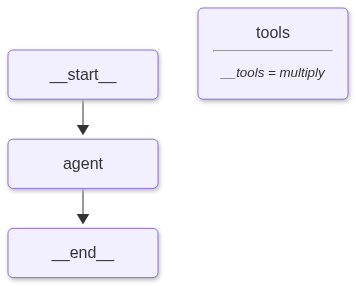

In [21]:
# ==========================================
# 6. LANGGRAPH: BUILD WORKFLOW
# ==========================================

builder = StateGraph(AgentState)

builder.add_node("agent", agent_node)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "agent")

builder.add_conditional_edges(
    "agent",
    route_after_agent
)

builder.add_edge("tools", "agent")

graph = builder.compile()


display(Image(graph.get_graph().draw_mermaid_png()))

In [16]:
# ==========================================
# 7. RUN
# ==========================================

result = graph.invoke({
    "messages": [
        ("user", "Multiply 12 by 5")
    ],
    "steps": 0
})

print("\nFINAL ANSWER:")
print(result["messages"][-1].content)

[LOG] Agent execution: 1
[LOG] Agent execution: 2

FINAL ANSWER:
The product of 12 and 5 is **60**.
